# Học hồi quy với dữ liệu giá nhà California

Notebook này dạy từng bước: xử lý giá trị thiếu và cột chữ bằng pipeline, linear regression, Ridge, Lasso, KNN regression và Gradient Boosting.

Dữ liệu: 20.640 khu dân cư (block group) ở California theo điều tra dân số năm 1990. Mỗi dòng là một khu, không phải một căn nhà. Biến mục tiêu là median_house_value, giá trị nhà trung vị của khu (USD). Nguồn: bản CSV trong sách Hands-On Machine Learning của Aurélien Géron, có thêm cột ocean_proximity và một số ô trống so với bản trong scikit-learn.

Chuẩn bị:
1. Đặt file data4.csv cùng thư mục với notebook.
2. Cài thư viện nếu chưa có: pip install pandas numpy matplotlib seaborn scikit-learn

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

## Bước 1: Đọc dữ liệu

Mục tiêu: đưa file CSV vào DataFrame và kiểm tra kích thước.

Kiến thức: pd.read_csv đọc file thành bảng. df.shape trả về (số dòng, số cột).

Kết quả mong đợi: (20640, 10).

In [2]:
df = pd.read_csv('data4.csv')
print(df.shape)
print(df.head())

(20640, 10)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


## Bước 2: Kiểu dữ liệu, ô trống và cột chữ

Mục tiêu: tìm cột bị thiếu dữ liệu và xem cột chữ có những giá trị nào.

Kiến thức: isna().sum() đếm ô trống theo từng cột. Cột ocean_proximity là cột chữ (categorical), cần mã hóa trước khi đưa vào mô hình.

Kết quả mong đợi: chỉ total_bedrooms bị thiếu, 207 ô. ocean_proximity có 5 nhóm: <1H OCEAN 9136, INLAND 6551, NEAR OCEAN 2658, NEAR BAY 2290 và ISLAND chỉ 5 khu.

Câu hỏi: một nhóm chỉ có rất ít mẫu (ISLAND) sẽ gây vấn đề gì khi chia train/test?

In [3]:
df.info()
na = df.isna().sum()
print(na[na > 0])
print(df['ocean_proximity'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
total_bedrooms    207
dtype: int64
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


## Bước 3: Phân phối biến mục tiêu

Mục tiêu: xem giá nhà phân bố thế nào và phát hiện giá trị bị chặn trên.

Kiến thức: khi thu thập dữ liệu, giá trị trên một ngưỡng có thể bị ghi bằng đúng ngưỡng đó (capping). Ở đây, mọi khu có giá trên 500.000 USD bị ghi là 500.001. Mô hình sẽ không học được giá thật của các khu này.

Kết quả mong đợi: giá trung bình khoảng 206.856 USD, trung vị 179.700 USD, thấp nhất 14.999 USD. Có 965 khu bị chặn ở 500.001 USD, tạo một cột cao bất thường ở cuối histogram.

count     20640.0
mean     206856.0
std      115396.0
min       14999.0
25%      119600.0
50%      179700.0
75%      264725.0
max      500001.0
Name: median_house_value, dtype: float64
Số khu bị chặn ở 500001: 965


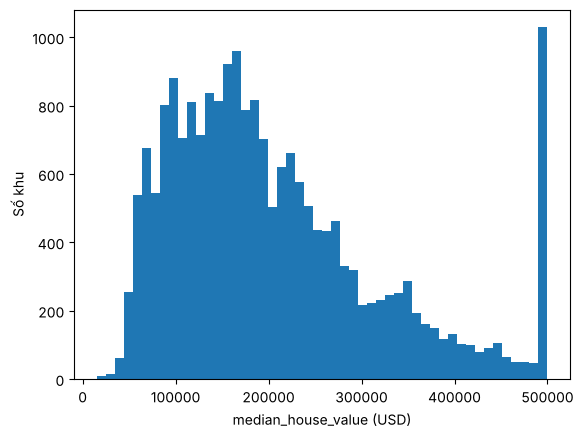

In [4]:
print(df['median_house_value'].describe().round(0))
print('Số khu bị chặn ở 500001:', (df['median_house_value'] >= 500001).sum())
plt.hist(df['median_house_value'], bins=50)
plt.xlabel('median_house_value (USD)')
plt.ylabel('Số khu')
plt.show()

## Bước 4: Bản đồ giá nhà

Mục tiêu: dùng tọa độ để thấy giá nhà phụ thuộc vào vị trí.

Kiến thức: scatter với x là kinh độ và y là vĩ độ cho ra hình bản đồ. Tham số c tô màu theo giá, s đặt kích thước điểm theo dân số.

Kết quả mong đợi: giá cao tập trung ở ven biển, quanh khu vực Los Angeles và vịnh San Francisco. Vùng nội địa phía đông có giá thấp hơn.

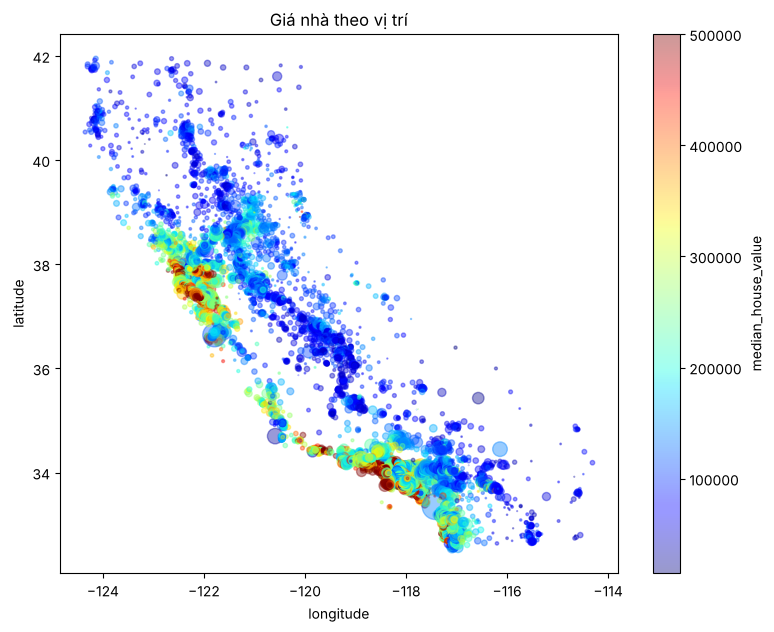

In [5]:
plt.figure(figsize=(9, 7))
plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'], cmap='jet',
            s=df['population'] / 100, alpha=0.4)
plt.colorbar(label='median_house_value')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.title('Giá nhà theo vị trí')
plt.show()

## Bước 5: Tạo feature mới và xem tương quan

Mục tiêu: tạo các tỷ lệ có ý nghĩa hơn số tổng, rồi xem cột nào liên quan nhất đến giá.

Kiến thức: total_rooms là tổng số phòng của cả khu, nên khu đông dân thì số này lớn mà không nói gì về nhà to hay nhỏ. Chia cho số hộ (households) cho ra số phòng trung bình mỗi hộ. Đây là feature engineering.

Kết quả mong đợi: median_income có tương quan cao nhất, khoảng 0,688. bedrooms_per_room khoảng -0,256, mạnh hơn total_bedrooms (0,050). rooms_per_household khoảng 0,152, mạnh hơn total_rooms (0,134).

Câu hỏi: vì sao bedrooms_per_room có tương quan âm với giá?

In [6]:
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']
print(df.select_dtypes('number').corr()['median_house_value'].sort_values(ascending=False).round(3))

median_house_value          1.000
median_income               0.688
rooms_per_household         0.152
total_rooms                 0.134
housing_median_age          0.106
households                  0.066
total_bedrooms              0.050
population_per_household   -0.024
population                 -0.025
longitude                  -0.046
latitude                   -0.144
bedrooms_per_room          -0.256
Name: median_house_value, dtype: float64


## Bước 6: Chia train và test

Mục tiêu: giữ lại 20% dữ liệu làm tập test.

Kiến thức: tách y ra trước. Mọi bước xử lý (điền ô trống, chuẩn hóa) sẽ nằm trong pipeline và chỉ học từ tập train.

Kết quả mong đợi: X_train có 16512 dòng và 12 cột, X_test có 4128 dòng.

In [7]:
y = df['median_house_value']
X = df.drop(columns='median_house_value')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(16512, 12) (4128, 12)


## Bước 7: Pipeline tiền xử lý

Mục tiêu: gom việc điền ô trống, chuẩn hóa và one-hot vào một đối tượng duy nhất.

Kiến thức: ColumnTransformer áp dụng các bước khác nhau cho các nhóm cột khác nhau. Cột số: SimpleImputer(strategy="median") điền ô trống bằng trung vị của tập train, rồi StandardScaler. Cột chữ: OneHotEncoder tạo mỗi giá trị thành một cột 0/1. handle_unknown="ignore" giúp không lỗi khi tập test có giá trị chưa gặp.

Kết quả mong đợi: sau khi biến đổi có 16 cột: 11 cột số và 5 cột one-hot của ocean_proximity.

In [8]:
num_cols = X_train.select_dtypes('number').columns.tolist()
cat_cols = ['ocean_proximity']
num_pipe = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
prep = ColumnTransformer([('num', num_pipe, num_cols),
                          ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
Xt = prep.fit_transform(X_train)
print(Xt.shape)
print(prep.get_feature_names_out())

(16512, 16)
['num__longitude' 'num__latitude' 'num__housing_median_age'
 'num__total_rooms' 'num__total_bedrooms' 'num__population'
 'num__households' 'num__median_income' 'num__rooms_per_household'
 'num__bedrooms_per_room' 'num__population_per_household'
 'cat__ocean_proximity_<1H OCEAN' 'cat__ocean_proximity_INLAND'
 'cat__ocean_proximity_ISLAND' 'cat__ocean_proximity_NEAR BAY'
 'cat__ocean_proximity_NEAR OCEAN']


## Bước 8: Linear regression và baseline

Mục tiêu: có con số đầu tiên để so sánh các mô hình sau.

Kiến thức: RMSE là căn bậc hai của sai số bình phương trung bình, cùng đơn vị với y (USD), phạt nặng các lỗi lớn. MAE là sai số tuyệt đối trung bình. Hàm rmse đã được định nghĩa ở bước 0. Baseline: luôn đoán bằng giá trung bình của tập train.

Kết quả mong đợi: RMSE khoảng 69.127 USD, MAE khoảng 49.645 USD, R² khoảng 0,635. Baseline đoán trung bình có RMSE khoảng 114.486 USD.

In [9]:
lin = Pipeline([('prep', prep), ('model', LinearRegression())])
lin.fit(X_train, y_train)
pred = lin.predict(X_test)
print('RMSE:', round(rmse(y_test, pred)), '| MAE:', round(mean_absolute_error(y_test, pred)),
      '| R²:', round(r2_score(y_test, pred), 3))
print('Baseline RMSE:', round(rmse(y_test, np.full(len(y_test), y_train.mean()))))

RMSE: 69127 | MAE: 49645 | R²: 0.635
Baseline RMSE: 114486


## Bước 9: Ridge: phạt hệ số lớn

Mục tiêu: thử regularization L2 với nhiều mức alpha.

Kiến thức: Ridge cộng thêm alpha nhân tổng bình phương các hệ số vào hàm mất mát. alpha = 0 giống linear regression. alpha lớn làm hệ số co về gần 0, mô hình đơn giản hơn. Dùng cross-validation để chọn alpha. scoring="neg_root_mean_squared_error" trả về RMSE mang dấu âm (sklearn luôn coi số lớn hơn là tốt hơn), nên cần đổi dấu.

Kết quả mong đợi: CV RMSE gần như không đổi từ alpha = 0,01 đến alpha = 100 (khoảng 67.850 đến 67.880). Đến alpha = 1000 thì lỗi tăng lên khoảng 69.043.

Câu hỏi: với 16.000 dòng và chỉ 16 cột, bạn có nghĩ regularization giúp nhiều không? Kết quả có khớp với dự đoán của bạn?

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    ridge = Pipeline([('prep', prep), ('model', Ridge(alpha=alpha))])
    s = -cross_val_score(ridge, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error').mean()
    print(f'alpha = {alpha:>7} | CV RMSE = {s:,.0f}')

alpha =    0.01 | CV RMSE = 67,859


alpha =     0.1 | CV RMSE = 67,857


alpha =       1 | CV RMSE = 67,849


alpha =      10 | CV RMSE = 67,852


alpha =     100 | CV RMSE = 67,880


alpha =    1000 | CV RMSE = 69,043


## Bước 10: Lasso: chọn feature tự động

Mục tiêu: thấy Lasso đưa một số hệ số về đúng 0.

Kiến thức: Lasso dùng phạt L1 (tổng giá trị tuyệt đối của hệ số). Khác với Ridge, L1 có thể đưa hệ số về đúng 0, tức là bỏ hẳn feature đó. Vì vậy Lasso vừa là mô hình vừa là cách chọn feature.

Kết quả mong đợi: alpha = 10 loại 1 hệ số, alpha = 100 loại 2, alpha = 1000 loại 5, alpha = 5000 loại 10 trên 16 hệ số và test RMSE tăng lên khoảng 74.032. Có thể xuất hiện ConvergenceWarning, bạn có thể bỏ qua.

In [11]:
for alpha in [10, 100, 1000, 5000]:
    lasso = Pipeline([('prep', prep), ('model', Lasso(alpha=alpha, max_iter=10000))])
    lasso.fit(X_train, y_train)
    coef = lasso.named_steps['model'].coef_
    print(f'alpha = {alpha:>5} | test RMSE = {rmse(y_test, lasso.predict(X_test)):,.0f} | số hệ số = 0: {(coef == 0).sum()}')
names = lasso.named_steps['prep'].get_feature_names_out()
print('Bị loại khi alpha = 5000:', list(names[coef == 0]))

alpha =    10 | test RMSE = 69,140 | số hệ số = 0: 1
alpha =   100 | test RMSE = 69,179 | số hệ số = 0: 2
alpha =  1000 | test RMSE = 69,596 | số hệ số = 0: 5
alpha =  5000 | test RMSE = 74,032 | số hệ số = 0: 10
Bị loại khi alpha = 5000: ['num__latitude', 'num__total_rooms', 'num__population', 'num__households', 'num__rooms_per_household', 'num__population_per_household', 'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_ISLAND', 'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN']


## Bước 11: Đọc hệ số của Ridge

Mục tiêu: biết feature nào làm giá tăng hoặc giảm.

Kiến thức: vì các cột số đã chuẩn hóa, hệ số cho biết giá thay đổi bao nhiêu USD khi feature tăng một độ lệch chuẩn. Có thể so sánh độ lớn các hệ số với nhau. Với cột one-hot, hệ số là chênh lệch so với mức trung bình của các nhóm.

Kết quả mong đợi: median_income có hệ số dương lớn nhất trong các cột số (khoảng 78.904). latitude (khoảng -56.587) và longitude (khoảng -56.222) có hệ số âm lớn nhất. ISLAND có hệ số khoảng 93.365 nhưng chỉ dựa trên vài khu.

Câu hỏi: latitude và longitude đều có hệ số âm lớn. Điều đó có nghĩa gì trên bản đồ ở bước 4?

In [12]:
ridge = Pipeline([('prep', prep), ('model', Ridge(alpha=1))])
ridge.fit(X_train, y_train)
coefs = pd.Series(ridge.named_steps['model'].coef_, index=ridge.named_steps['prep'].get_feature_names_out())
print(coefs.sort_values().round(0))

num__latitude                     -56587.0
num__longitude                    -56222.0
cat__ocean_proximity_INLAND       -48972.0
num__population                   -46284.0
cat__ocean_proximity_NEAR BAY     -19413.0
cat__ocean_proximity_<1H OCEAN    -13997.0
cat__ocean_proximity_NEAR OCEAN   -10983.0
num__population_per_household        746.0
num__total_bedrooms                 5436.0
num__total_rooms                    5879.0
num__rooms_per_household            7686.0
num__housing_median_age            14128.0
num__bedrooms_per_room             16804.0
num__households                    40074.0
num__median_income                 78904.0
cat__ocean_proximity_ISLAND        93365.0
dtype: float64


## Bước 12: KNN regression

Mục tiêu: dự đoán giá bằng trung bình giá của k khu giống nhất.

Kiến thức: KNeighborsRegressor lấy trung bình y của k điểm gần nhất. Vì dùng khoảng cách, chuẩn hóa là bắt buộc (pipeline prep đã làm việc này). KNN không giả định quan hệ tuyến tính, nên có thể học được hiệu ứng vị trí mà linear regression bỏ sót.

Kết quả mong đợi: k = 10 có CV RMSE thấp nhất, khoảng 60.885. Test RMSE khoảng 60.942, tốt hơn linear regression khoảng 8.000 USD.

In [13]:
knn_scores = {}
for k in [3, 5, 10, 20, 50]:
    knn = Pipeline([('prep', prep), ('model', KNeighborsRegressor(n_neighbors=k))])
    knn_scores[k] = -cross_val_score(knn, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error').mean()
    print(f'k = {k:>2} | CV RMSE = {knn_scores[k]:,.0f}')
best_k = min(knn_scores, key=knn_scores.get)
knn = Pipeline([('prep', prep), ('model', KNeighborsRegressor(n_neighbors=best_k))]).fit(X_train, y_train)
print('best_k =', best_k, '| test RMSE =', round(rmse(y_test, knn.predict(X_test))))

k =  3 | CV RMSE = 63,942


k =  5 | CV RMSE = 61,812


k = 10 | CV RMSE = 60,885


k = 20 | CV RMSE = 61,467


k = 50 | CV RMSE = 63,766
best_k = 10 | test RMSE = 60942


## Bước 13: Gradient Boosting

Mục tiêu: huấn luyện mô hình gồm nhiều cây nhỏ học nối tiếp nhau.

Kiến thức: random forest trồng các cây độc lập rồi lấy trung bình. Gradient boosting trồng cây lần lượt: mỗi cây mới học phần sai số (residual) mà các cây trước để lại. learning_rate thu nhỏ đóng góp của mỗi cây, n_estimators là số cây, max_depth thường nhỏ (3 đến 5). Bước này mất khoảng 30 giây đến 1 phút.

Kết quả mong đợi: RMSE khoảng 46.028 USD, MAE khoảng 30.297 USD, R² khoảng 0,838.

In [14]:
gb = Pipeline([('prep', prep), ('model', GradientBoostingRegressor(n_estimators=500, learning_rate=0.1,
                                                                    max_depth=4, random_state=42))])
gb.fit(X_train, y_train)
pred_gb = gb.predict(X_test)
print('RMSE:', round(rmse(y_test, pred_gb)), '| MAE:', round(mean_absolute_error(y_test, pred_gb)),
      '| R²:', round(r2_score(y_test, pred_gb), 3))

RMSE: 46028 | MAE: 30297 | R²: 0.838


## Bước 14: Số cây và overfitting

Mục tiêu: xem lỗi trên train và test thay đổi thế nào khi thêm cây.

Kiến thức: staged_predict trả về dự đoán sau 1 cây, 2 cây, ..., n cây. Lỗi train luôn giảm. Lỗi test giảm rồi đi ngang hoặc tăng lại khi mô hình bắt đầu overfit. Vì staged_predict thuộc về mô hình (không phải pipeline), cần transform X trước bằng bước prep đã fit.

Kết quả mong đợi: RMSE test thấp nhất khoảng 46.023 ở 497 cây, nên lỗi test vẫn còn giảm rất chậm ở cuối. Với 500 cây, RMSE train khoảng 34.162 và RMSE test khoảng 46.028.

Câu hỏi: lỗi test vẫn giảm ở cây thứ 500. Bạn có nên thử 1000 cây không? Chênh lệch giữa lỗi train và lỗi test nói gì?

RMSE test nhỏ nhất: 46023 tại 497 cây
Với 500 cây: train 34162 | test 46028


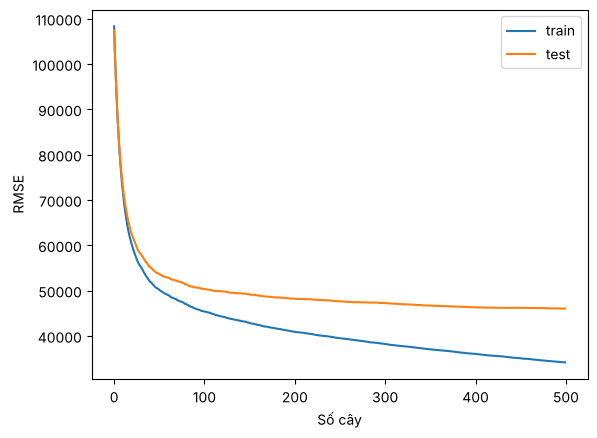

In [15]:
model = gb.named_steps['model']
Xtr = gb.named_steps['prep'].transform(X_train)
Xte = gb.named_steps['prep'].transform(X_test)
train_err = [rmse(y_train, p) for p in model.staged_predict(Xtr)]
test_err = [rmse(y_test, p) for p in model.staged_predict(Xte)]
best_n = int(np.argmin(test_err)) + 1
print('RMSE test nhỏ nhất:', round(min(test_err)), 'tại', best_n, 'cây')
print('Với 500 cây: train', round(train_err[-1]), '| test', round(test_err[-1]))

plt.plot(train_err, label='train')
plt.plot(test_err, label='test')
plt.xlabel('Số cây')
plt.ylabel('RMSE')
plt.legend()
plt.show()

## Bước 15: Permutation importance

Mục tiêu: xem feature nào quan trọng nhất với Gradient Boosting.

Kiến thức: permutation_importance xáo trộn từng cột của X_test rồi xem lỗi tăng bao nhiêu. Gọi trên cả pipeline gb nên các cột là cột gốc (trước one-hot). Bước này mất khoảng 30 giây.

Kết quả mong đợi: longitude (khoảng 107.000) và latitude (khoảng 107.000) đứng đầu, sau đó là median_income (khoảng 34.560). total_rooms và population gần như không quan trọng (dưới 1.000).

In [16]:
perm = permutation_importance(gb, X_test, y_test, n_repeats=5, random_state=42,
                              scoring='neg_root_mean_squared_error')
print(pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).round(0))

longitude                   107147.0
latitude                    106921.0
median_income                34560.0
population_per_household     14850.0
ocean_proximity              12753.0
bedrooms_per_room             9723.0
rooms_per_household           5641.0
housing_median_age            4611.0
households                    1193.0
total_bedrooms                 938.0
total_rooms                    742.0
population                     367.0
dtype: float64


## Bước 16: Dự đoán và giá trị thật

Mục tiêu: xem mô hình sai nhiều ở đâu.

Kiến thức: scatter giữa giá thật và giá dự đoán. Nếu đúng hoàn toàn, mọi điểm nằm trên đường chéo y = x.

Kết quả mong đợi: các điểm ở giá thật 500.001 tạo thành một cột dọc, mô hình đoán thấp hơn nhiều. RMSE của 179 khu bị chặn khoảng 96.896, còn các khu khác khoảng 42.297.

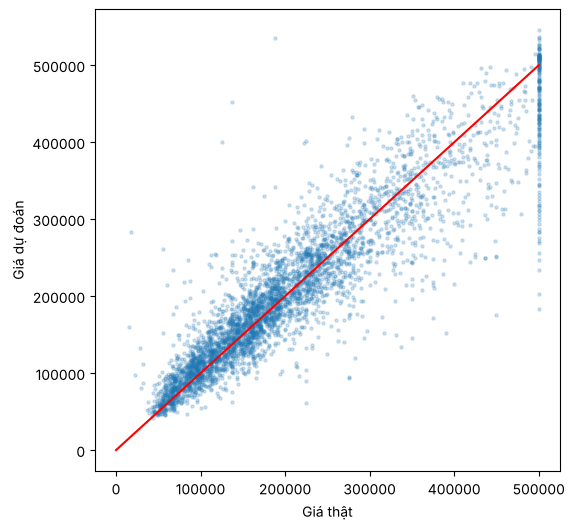

RMSE khu bị chặn: 96896 | số khu: 179
RMSE các khu còn lại: 42297


In [17]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_gb, alpha=0.2, s=5)
plt.plot([0, 500001], [0, 500001], color='red')
plt.xlabel('Giá thật')
plt.ylabel('Giá dự đoán')
plt.show()

capped = y_test >= 500001
print('RMSE khu bị chặn:', round(rmse(y_test[capped], pred_gb[capped])), '| số khu:', capped.sum())
print('RMSE các khu còn lại:', round(rmse(y_test[~capped], pred_gb[~capped])))

## Bước 17: Bảng so sánh các mô hình

Mục tiêu: ghép kết quả các mô hình vào một bảng.

Kiến thức: dùng cùng tập test cho mọi mô hình để so sánh công bằng.

Kết quả mong đợi: Linear, Ridge và Lasso gần như bằng nhau (RMSE khoảng 69.100 đến 69.200, R² 0,635). KNN k = 10 có RMSE khoảng 60.942. Gradient Boosting tốt nhất với RMSE khoảng 46.028 và R² khoảng 0,838.

Câu hỏi: Gradient Boosting tốt nhất nhưng khó giải thích hơn. Khi nào bạn vẫn chọn Ridge?

In [18]:
models = {
    'Linear': lin,
    'Ridge alpha=1': ridge,
    'Lasso alpha=100': Pipeline([('prep', prep), ('model', Lasso(alpha=100, max_iter=10000))]).fit(X_train, y_train),
    f'KNN k={best_k}': knn,
    'Gradient Boosting': gb,
}
rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append({'Mô hình': name, 'RMSE': round(rmse(y_test, p)), 'MAE': round(mean_absolute_error(y_test, p)),
                 'R2': round(r2_score(y_test, p), 3)})
print(pd.DataFrame(rows).to_string())

             Mô hình   RMSE    MAE     R2
0             Linear  69127  49645  0.635
1      Ridge alpha=1  69135  49652  0.635
2    Lasso alpha=100  69179  49649  0.635
3           KNN k=10  60942  40723  0.717
4  Gradient Boosting  46028  30297  0.838


## Bước 18: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Dự đoán np.log(y) thay vì y, rồi đổi lại bằng np.exp trước khi tính RMSE. Linear regression có tốt hơn không?
2. Bỏ các khu có giá 500001 khỏi tập train rồi huấn luyện lại Gradient Boosting. RMSE trên các khu còn lại thay đổi thế nào?
3. Thử HistGradientBoostingRegressor (from sklearn.ensemble import HistGradientBoostingRegressor). Nó nhanh hơn bao nhiêu?
4. Viết ba câu tiếng Anh tóm tắt bảng ở bước 17. Ví dụ: "Gradient boosting reduced the test RMSE from ... (linear regression) to ... USD."
